## TASK 1:

The goal of this task is to preprocess the GenreAll dataset, and try to obtain the best accuracy results for the clasification task, while trying different models, doing hyperparameter search, trying different feature selection tecniques, and assessing the overfitting

In [ ]:
# only needed for colab
!git clone https://github.com/annacp04/music-genre-classification.git
%cd music-genre-classification

In [1]:
import pandas as pd

import os, re, joblib
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

# Import our implementation classes
from FeatureSelection import *
from Preprocessing import * 
from Models import *
from grid_config import * 

In [2]:
# Preprocessing does the Train/Test split (with the train we to CV later), 
# Encodes the categorical features and target column...
genre_all_df = pd.read_csv('GenreAll.csv', sep=',')
target_column = " genre"

processing_genre_all = Preprocessing(genre_all_df, target_column)
processing_genre_all.run()
X_train, X_test, y_train, y_test = processing_genre_all.get_data()

=== Cleaning ===
Rows without target removed: 0
Duplicated rows removed: 13
Final shape: (980, 241)

X: (980, 240) | y: (980,)

=== Train / test split (80% / 20%) ===
Train: (784, 240) | Test: (196, 240)

Class proportions (train vs test):
       train   test
genre              
blu    0.102  0.102
cla    0.094  0.097
cou    0.102  0.102
dis    0.101  0.102
hip    0.101  0.097
jaz    0.102  0.102
met    0.094  0.097
pop    0.101  0.097
reg    0.101  0.102
roc    0.102  0.102

=== Categorical encoding ===
highlevel_speech_music_value: 2 categories
highlevel_voice_instrumental_value: 2 categories
tonal_key_mode_value: 2 categories
Features after encoding: 243

=== Constant columns removed (2) ===
['spectral_barkbands_25_dvar', 'spectral_barkbands_25_var']

=== Target encoding ===
0 -> blu
1 -> cla
2 -> cou
3 -> dis
4 -> hip
5 -> jaz
6 -> met
7 -> pop
8 -> reg
9 -> roc


We evaluate all the different models proposed in class, and for each one we try different hyperparameters (for example the number of neightbours in KNN). The implementations of the models are found in ``Models.py``. 

Then we also try some of the methods for Feature Selection to try and simplify the model therefore having less overfitting or complexity of the models (the feature selection algorithms tried are explained in ``FeatureSelection.py``). 

Of course there is a lot of methods, and hyperparameters we could try, but given that we do a GridSearch, the combinatorial number if we tried that many parameters would make that the training would be unfeasable. This is why we only try a few combination of them. 

Apply the GridSeach to our data

In [3]:
models = Models(
    X_train, y_train,
    n_splits=10,
    random_state=42,
    n_jobs=-1,
)
n = models.X.shape[1]                       
k_values = [k for k in (10, 20, 30, 40) if k < n]

models.build_models()
grids = build_param_grids(models.fs, k_values=k_values)
print_grid_sizes(grids)

results = {}
for name, grid in grids.items():
    best, summary = models.grid_search(name, grid, nested=False, set_best=False, inner_splits=10)
    results[name] = summary
    print(name)
    print(best_per_selector(summary))

              Model  Combinaciones  Fits (nested=False)  Fits (nested=True)
Logistic Regression             24                  240                2640
                KNN             40                  400                4400
      Decision Tree             24                  240                2640
          ANN (MLP)             12                  120                1320
      Random Forest              8                   80                 880
        Extra Trees              8                   80                 880
  Gradient Boosting              4                   40                 440
           AdaBoost              4                   40                 440
    Voting Ensemble              2                   20                 220
              TOTAL            126                 1260               13860


Best parameters (full train): {'model__C': 0.1, 'selector': PCA(n_components=0.95, random_state=42, svd_solver='full'), 'selector__n_components': 0.99}
Logistic Regression
        Selector  mean_test_score  std_test_score  \
0        PCA var         0.821454        0.044967   
1   L1 logística         0.820172        0.045573   
2  Sin selección         0.818858        0.046155   
3          ANOVA         0.747517        0.039964   

                                              Params  
0  {'model__C': 0.1, 'selector__n_components': 0.99}  
1   {'model__C': 0.1, 'selector__estimator__C': 0.1}  
2                                  {'model__C': 0.1}  
3                 {'model__C': 1, 'selector__k': 40}  
Best parameters (full train): {'model__n_neighbors': 9, 'model__weights': 'distance', 'selector': LinearDiscriminantAnalysis()}
KNN
        Selector  mean_test_score  std_test_score  \
0            LDA         0.794628        0.059529   
1   L1 logística         0.758909        0.051990

We store the combinations in the results folder

BEST COMBINATION OF EACH MODEL(CV)
              Model      Selector  mean_test_score  std_test_score
    Voting Ensemble Sin selección         0.836741        0.038685
Logistic Regression       PCA var         0.821454        0.044967
  Gradient Boosting Sin selección         0.815044        0.031391
        Extra Trees Sin selección         0.811230        0.053764
      Random Forest Sin selección         0.806183        0.063877
          ANN (MLP) Sin selección         0.794693        0.050377
                KNN           LDA         0.794628        0.059529
           AdaBoost Sin selección         0.744920        0.057890
      Decision Tree Sin selección         0.603229        0.066254

 BEST COMBINATION OF EACH SELECTOR, INSIDE EACH MODEL(CV)

ANN (MLP)
     Selector  mean_test_score  std_test_score
Sin selección           0.7947          0.0504
      PCA var           0.7909          0.0587

AdaBoost
     Selector  mean_test_score  std_test_score
Sin selección           0.7

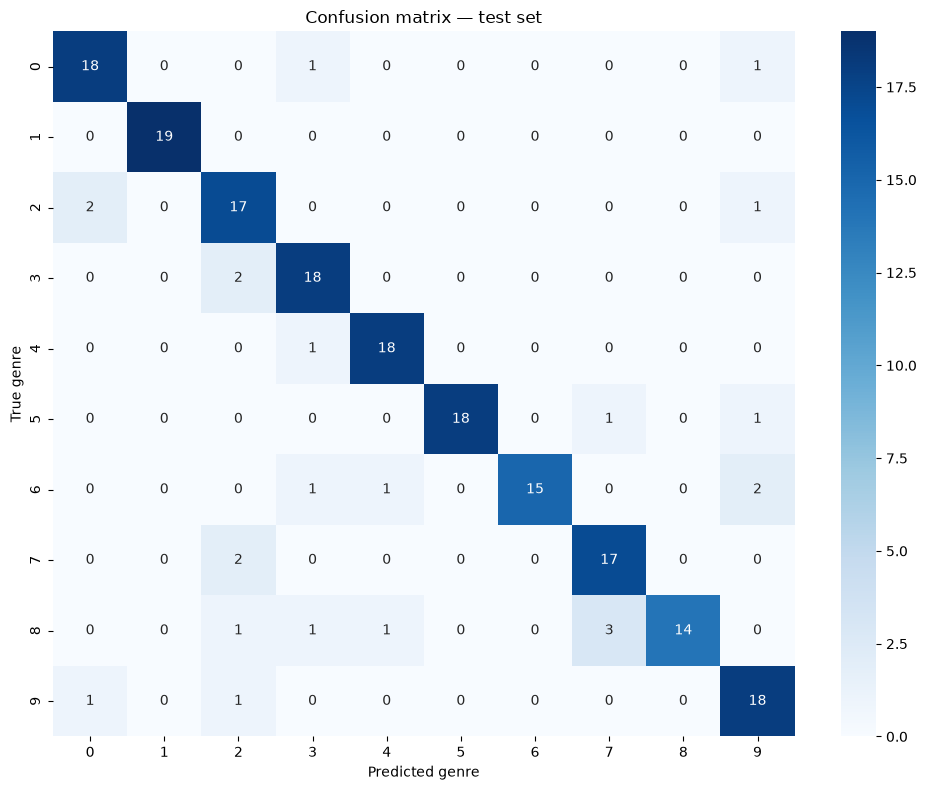

array([7, 3, 0, 2, 9, 0, 7, 9, 4, 9, 5, 9, 9, 4, 8, 3, 2, 7, 6, 9, 7, 7,
       1, 6, 5, 1, 2, 3, 4, 4, 2, 9, 3, 8, 7, 2, 6, 5, 5, 8, 3, 1, 7, 2,
       1, 5, 0, 3, 3, 0, 0, 5, 2, 1, 7, 4, 6, 4, 4, 0, 0, 6, 7, 3, 4, 0,
       3, 2, 7, 8, 9, 1, 3, 6, 0, 7, 6, 4, 8, 1, 0, 1, 2, 0, 6, 7, 5, 2,
       1, 9, 4, 1, 5, 3, 1, 3, 8, 9, 0, 5, 3, 2, 9, 0, 6, 9, 1, 6, 7, 1,
       4, 3, 9, 3, 8, 4, 3, 3, 2, 4, 9, 1, 5, 2, 1, 7, 2, 5, 2, 4, 1, 4,
       9, 2, 1, 2, 9, 9, 5, 2, 9, 2, 1, 7, 2, 4, 0, 0, 0, 8, 7, 0, 9, 9,
       1, 2, 8, 6, 7, 0, 9, 5, 8, 4, 3, 4, 2, 0, 5, 2, 4, 9, 3, 3, 0, 6,
       6, 3, 5, 0, 7, 6, 5, 7, 6, 8, 4, 9, 8, 5, 7, 7, 5, 3, 8, 8])

In [4]:
os.makedirs("results/pipelines", exist_ok=True)


def tidy_cv(name, summary):
    cv = summary["cv_results"].reset_index(drop=True)
    params = pd.DataFrame(
        [{k: v for k, v in p.items() if k != "selector"} for p in cv["params"]]
    )
    head = pd.DataFrame({
        "Model": name,
        "Selector": cv["params"].map(lambda p: selector_label(p["selector"])),
    })
    return pd.concat(
        [head, cv[["mean_test_score", "std_test_score", "rank_test_score"]], params],
        axis=1,
    )

per_model = {n: tidy_cv(n, s) for n, s in results.items()}
for n, df in per_model.items():
    df.to_csv(f"results/cv_{re.sub(r'\W+', '_', n)}.csv", index=False)

all_cv = pd.concat(per_model.values(), ignore_index=True)
all_cv.to_csv("results/cv_all_combinations.csv", index=False)

# BEST PER MODEL: el mejor de cada modelo, sin importar el selector
ranked = all_cv.sort_values("mean_test_score", ascending=False)

best_per_model = ranked.groupby("Model", sort=False).head(1).reset_index(drop=True)
best_per_model_selector = (
    ranked.groupby(["Model", "Selector"], sort=False).head(1)
    .sort_values(["Model", "mean_test_score"], ascending=[True, False])
    .reset_index(drop=True)
)
best_per_model.to_csv("results/best_per_model.csv", index=False)
best_per_model_selector.to_csv("results/best_per_model_selector.csv", index=False)

print("BEST COMBINATION OF EACH MODEL(CV)")
print(best_per_model[["Model", "Selector", "mean_test_score", "std_test_score"]]
      .to_string(index=False))

print("\n BEST COMBINATION OF EACH SELECTOR, INSIDE EACH MODEL(CV)")
for model, g in best_per_model_selector.groupby("Model", sort=False):
    print(f"\n{model}")
    print(g[["Selector", "mean_test_score", "std_test_score"]]
          .to_string(index=False, float_format="{:.4f}".format))

# RETRAIN THE WINNER OF EACH MODEL WITH ALL THE TRAIN 
tuned = {}
for name, s in results.items():
    pipe = clone(models.models[name]).set_params(**s["best_params"])
    pipe.fit(models.X, models.y)
    tuned[name] = pipe
    fname = re.sub(r"\W+", "_", name)
    joblib.dump(pipe, f"results/pipelines/{fname}.joblib")

# TEST
Xt = models._align(X_test)
rows = []
for _, r in best_per_model.iterrows():
    pred = tuned[r["Model"]].predict(Xt)
    rows.append({
        "Model": r["Model"],
        "Selector": r["Selector"],
        "CV Acc": r["mean_test_score"],
        "Test Acc": accuracy_score(y_test, pred),
        "Test F1": f1_score(y_test, pred, average="macro"),
    })
test_table = pd.DataFrame(rows).sort_values("CV Acc", ascending=False)
test_table.to_csv("results/test_best_per_model.csv", index=False)
print("\nTEST ")
print(test_table.to_string(index=False, float_format="{:.4f}".format))

# LOOK AT THE CONFUSION MATRIX of the best one
elegido = best_per_model.loc[0, "Model"]       
models.best_model, models.best_model_name = tuned[elegido], f"{elegido} (tuned)"
models.evaluate_on_test(X_test, y_test)

The best method seems to be Voting Ensemble, achieving a 0.87 accuracy in the Test set

### Overfitting assessment: 

From both the cross-validation gridsearch and also the evaluation on the final test set we can extract a lot of conclusions. First of all, the test performance is higher than the cross validation for all the models. This is very important and means, first of all, that when we grab all the train data we obtain better results, and then that the hyperparameter search did not overfit the validation folds (also thanks to the cross validation). 


Evaluating 9 pipelines with 10-fold stratified CV on the training set...
  - Logistic Regression (tuned)
  - KNN (tuned)
  - Decision Tree (tuned)
  - ANN (MLP) (tuned)
  - Random Forest (tuned)
  - Extra Trees (tuned)
  - Gradient Boosting (tuned)
  - AdaBoost (tuned)
  - Voting Ensemble (tuned)

CROSS-VALIDATION RESULTS
                       Name  Train Acc  Val Acc  Val Acc Std    Gap  Val F1  N features
    Voting Ensemble (tuned)     1.0000   0.8367       0.0387 0.1633  0.8377    241.0000
Logistic Regression (tuned)     0.9837   0.8215       0.0450 0.1622  0.8220    137.3000
  Gradient Boosting (tuned)     1.0000   0.8150       0.0314 0.1850  0.8180    241.0000
        Extra Trees (tuned)     1.0000   0.8112       0.0538 0.1888  0.8118    241.0000
      Random Forest (tuned)     1.0000   0.8062       0.0639 0.1938  0.8073    241.0000
          ANN (MLP) (tuned)     0.9539   0.7947       0.0504 0.1593  0.7944    241.0000
                KNN (tuned)     1.0000   0.7946       0.0595

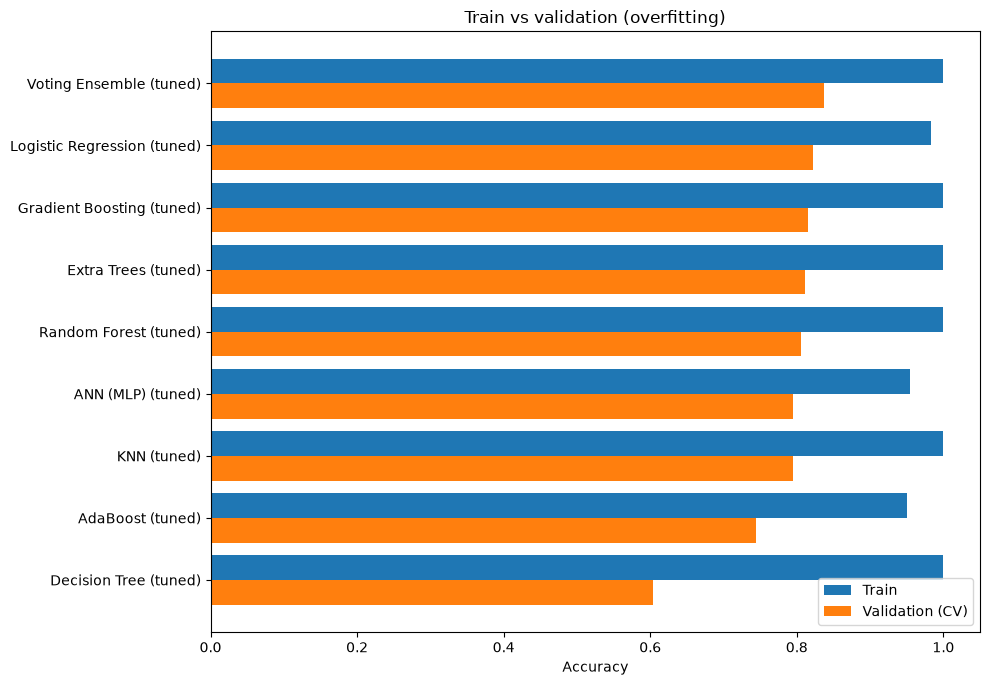

In [5]:
tuned_names = []
for name, pipe in tuned.items():
    sel = selector_label(results[name]["best_params"]["selector"])
    models.add_model(f"{name} (tuned)", clone(pipe), model=name, selector=sel)
    tuned_names.append(f"{name} (tuned)")

gap_table = models.evaluate_all(names=tuned_names)
models.plot_gap()

In this graphic we can see that all models seem to achieve a 95% or more accuracy in the training data, even though we try to select less variables to not overfit, and also trying different hyperparameters that can make a model simpler (like the lenght of a Decision Tree, or the number of neurons in the MLP). 

Keeping that in mind, the model that seems more overfitted is the Decision Tree, having the worst accuracy for validation, and the ones that have more consistent results are Logistic Regression and Voting. 

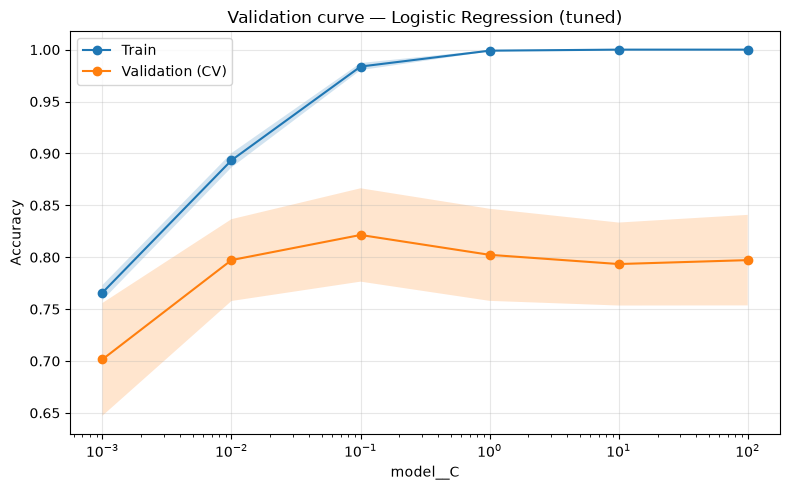

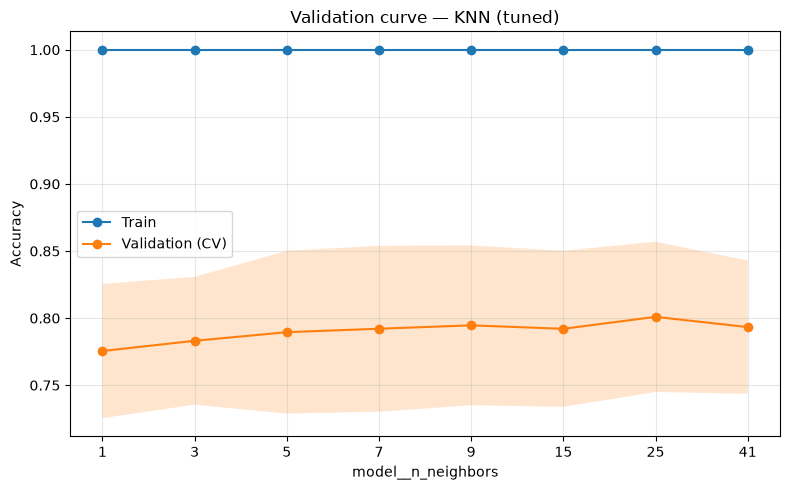

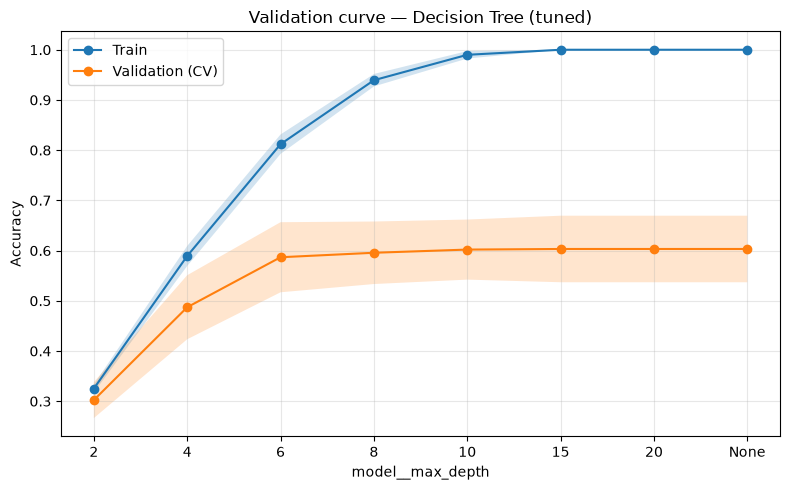

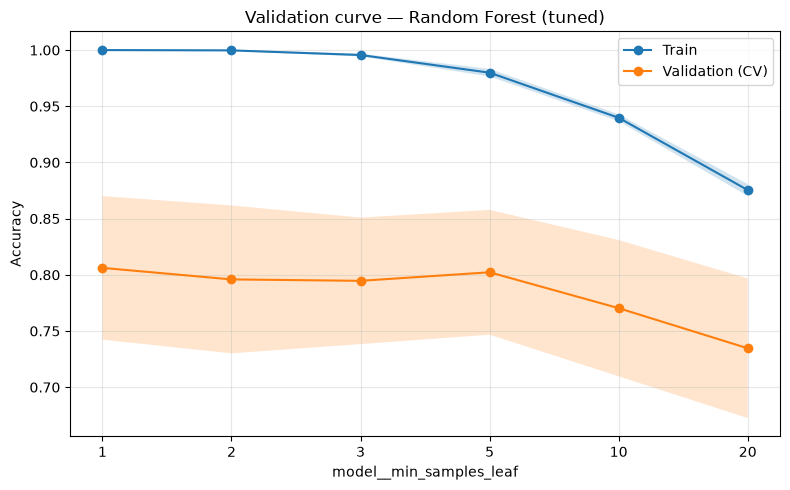

,model__min_samples_leaf,Train,Validation,Val Std
0,1,1.000000,0.806183,0.063877
1,2,0.999717,0.795927,0.065799
2,3,0.995606,0.794661,0.056272
3,5,0.979876,0.802272,0.055544
4,10,0.939768,0.770334,0.060640
5,20,0.875425,0.734648,0.062117


In [6]:
models.validation_curve("Logistic Regression (tuned)", "model__C", np.logspace(-3, 2, 6), log_x=True)
models.validation_curve("KNN (tuned)", "model__n_neighbors", [1, 3, 5, 7, 9, 15, 25, 41])
models.validation_curve("Decision Tree (tuned)", "model__max_depth", [2, 4, 6, 8, 10, 15, 20, None])
models.validation_curve("Random Forest (tuned)", "model__min_samples_leaf", [1, 2, 3, 5, 10, 20])

In these graphics we have observed that changin the different parameters like we did in the GridSearch, changes both the accuracy of the train and val partitions but also the difference between them. In the case of overfitting, we might prefer a model that has 93% in the train and then 77% in the validation that one that has 100% in the train and then just 2% higher than the previous validation. 

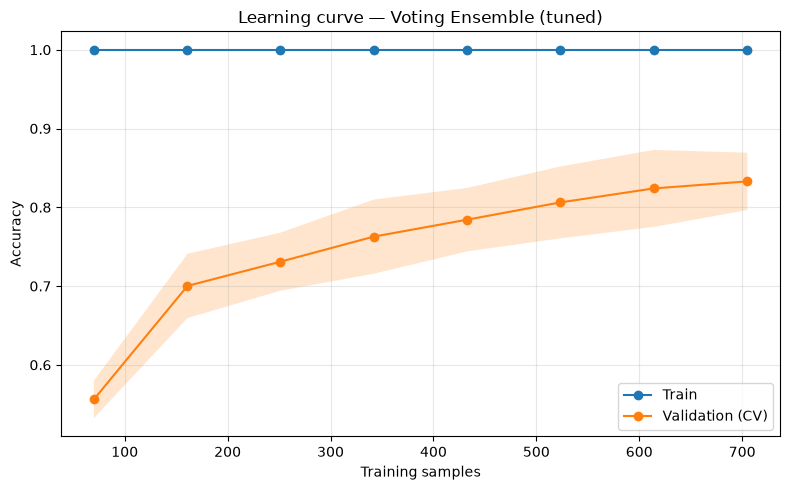

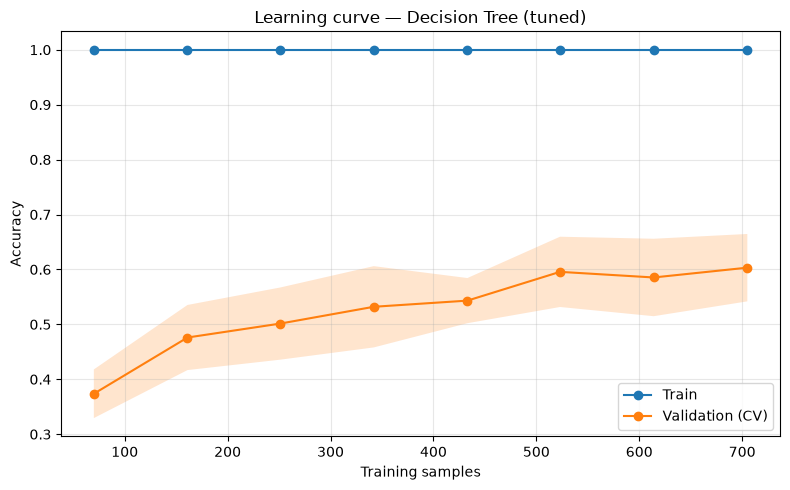

,Train samples,Train,Validation,Gap
0,70,1.0,0.373645,0.626355
1,161,1.0,0.476047,0.523953
2,251,1.0,0.501379,0.498621
3,342,1.0,0.532003,0.467997
4,433,1.0,0.543216,0.456784
5,523,1.0,0.595602,0.404398
6,614,1.0,0.585378,0.414622
7,705,1.0,0.603229,0.396771


In [7]:
models.learning_curve("Voting Ensemble (tuned)")
models.learning_curve("Decision Tree (tuned)")

Logistic Regression + anova k=10
Logistic Regression + anova k=20
Logistic Regression + anova k=40
Logistic Regression + anova k=60
Logistic Regression + anova k=100
Logistic Regression + anova k=150
Logistic Regression + anova k=200
Logistic Regression + anova k=240


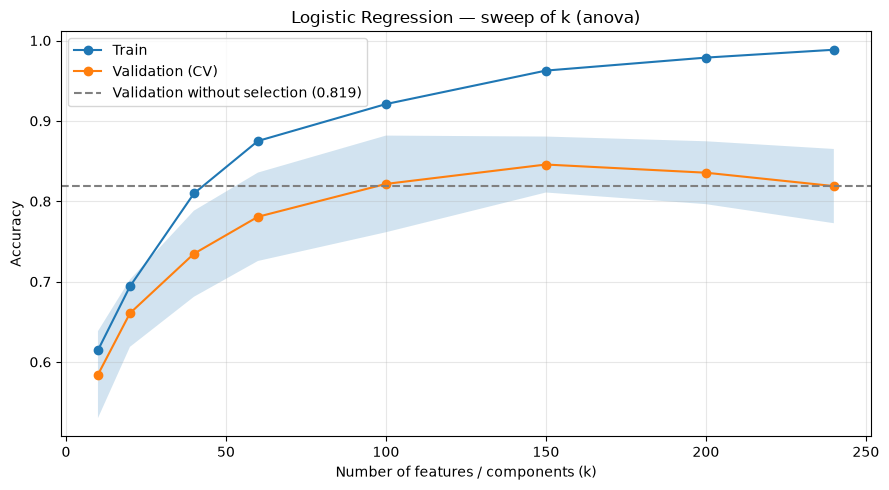

,k,Train Acc,Val Acc,Val Acc Std,Gap,Val F1,Val F1 Std,N features
0,10,0.614656,0.584226,0.054081,0.030430,0.579029,0.054688,10.0
1,20,0.694017,0.660646,0.041839,0.033371,0.660163,0.042280,20.0
2,40,0.809665,0.734697,0.053569,0.074969,0.734165,0.054655,40.0
3,60,0.874997,0.780672,0.055003,0.094325,0.781748,0.054686,60.0
4,100,0.920918,0.821551,0.060132,0.099367,0.823801,0.058165,100.0
5,150,0.962585,0.845683,0.034822,0.116902,0.845683,0.034265,150.0
6,200,0.978742,0.835508,0.039122,0.143234,0.835829,0.039232,200.0
7,240,0.988521,0.818841,0.046194,0.169680,0.819692,0.045978,240.0


In [8]:
models.sweep_k("logistic", "anova", k_values=(10, 20, 40, 60, 100, 150, 200, 240), model_params={"C": 0.1})

## CONCLUSIONS

### Setup

The GenreAll dataset was split once into **80% train (784 songs)** and **20% test (196 songs)**. Every model is a pipeline of **standardization → optional feature selector → classifier**. All preprocessing is fitted only on the training folds, so no information leaks into validation. Hyperparameters and the selector were tuned with a grid search on the training set. The selected configuration of each algorithm was then re-evaluated with **10-fold stratified cross-validation**. The test set was used only once, at the end.

### Results

Because the classes are balanced, accuracy is a fair metric. Apart from the Decision Tree, all models fall between 0.74 and 0.84 in the validation:

| Model | Selector | Train acc | Val acc (10-fold) | Gap | Test acc | Test F1 |
|---|---|---|---|---|---|---|
| **Voting Ensemble** | none | 1.000 | **0.837 ± 0.039** | 0.163 | **0.878** | **0.879** |
| Logistic Regression | PCA (99% variance) | 0.984 | 0.821 ± 0.045 | 0.162 | 0.842 | 0.843 |
| Gradient Boosting | none | 1.000 | 0.815 ± 0.031 | 0.185 | 0.837 | 0.842 |
| Extra Trees | none | 1.000 | 0.811 ± 0.054 | 0.189 | 0.821 | 0.824 |
| Random Forest | none | 1.000 | 0.806 ± 0.064 | 0.194 | 0.837 | 0.838 |
| ANN (MLP) | none | 0.954 | 0.795 ± 0.050 | 0.159 | 0.816 | 0.820 |
| KNN | LDA (9 comp.), k = 9 | 1.000 | 0.795 ± 0.060 | 0.205 | 0.806 | 0.811 |
| AdaBoost | none | 0.951 | 0.745 ± 0.058 | 0.206 | 0.745 | 0.753 |
| Decision Tree | none | 1.000 | 0.603 ± 0.066 | 0.397 | 0.648 | 0.654 |

### Overfitting analysis

As we have stated before, there is a big gap between train and validation, but with so many features for so few songs this is normal. However, the size of the gap alone doesn't say how bad the overfitting is. For example, the Voting Ensemble has a perfect training score and still has the best validation score. What matters is how validation accuracy reacts when model complexity changes.

#### Logistic Regression 

With strong regularization (C = 0.001), the model **underfits**: train 0.77, validation 0.70, small gap. As C increases, both scores rise until **C = 0.1, where validation peaks at 0.82**. For C ≥ 1, the model fits the training set perfectly (train = 1.00), and validation accuracy drops to about 0.79–0.80. This is overfitting in its classic form, and regularization is what controls it. The selected value, C = 0.1, sits exactly at the validation peak. 

#### Decision Tree

At depth 2 the tree underfits (0.33 / 0.30). From depth 6 onward, validation accuracy plateaus at about 0.59–0.60, while training accuracy keeps rising to 1.00 at depth 15. Extra depth only memorizes the training set and brings no gain on new songs, so the gap grows from 0.02 to about 0.40. A depth of 6 would give practically the same validation accuracy with a much smaller gap.

The learning curve shows the same pattern. Training accuracy stays at 1.0 for every training size. A single tree is intrinsically unstable: small changes in the data produce very different trees. Neither pruning nor more data closes this gap. Reducing variance by averaging many trees does, which is why Random Forest reaches 0.81 with the same type of base learner.

#### Random Forest

With `min_samples_leaf = 1`, the forest fits the training set perfectly but also reaches its **highest validation accuracy (0.806)**. Increasing the minimum leaf size to 5 lowers training accuracy (0.98) without changing validation (0.80). Beyond that, both curves drop together (0.77 at 10, 0.73 at 20), which means underfitting. Constraining the trees therefore does not help: averaging many decorrelated trees already controls the variance. The gap of 0.19 reflects memorization by the individual trees, not a loss of generalization. The same reasoning applies to Extra Trees and to the tree ensembles in the Voting Ensemble.

#### Feature selection and overfitting

The ANOVA sweep with Logistic Regression (C = 0.1) shows a clear effect:

| k | Train acc | Val acc | Gap |
|---|---|---|---|
| 10 | 0.615 | 0.584 | 0.030 |
| 40 | 0.810 | 0.735 | 0.075 |
| 100 | 0.921 | 0.822 | 0.099 |
| **150** | 0.963 | **0.846** | 0.117 |
| 200 | 0.979 | 0.836 | 0.143 |
| 240 (all) | 0.989 | 0.819 | 0.170 |

With few features (k = 10–40), the model **underfits**: train and validation are both low and close. As k grows, the gap increases monotonically, from 0.03 at k = 10 to 0.17 with all 240 features. Validation accuracy **peaks at k = 150 (0.846 ± 0.035)** and then declines to 0.819 when all features are used. Removing the roughly 90 least discriminative descriptors therefore improves validation accuracy by about 2.7 points and reduces the gap from 0.17 to 0.12. Feature selection does reduce overfitting for the linear model. In the grid search, however, L1 (0.820), PCA (0.821) and no selection (0.819) give practically the same result, so only a well-chosen filter improves the linear model.

This also corrects an earlier impression: with k limited to 10–40, ANOVA looked harmful, but that was only because k was too small.

For the tree-based models, feature selection does not help. Using all the features is actually slightly better (Extra Trees 0.811 vs 0.805 with the correlation filter, Random Forest 0.806 vs 0.791, Gradient Boosting 0.815 vs 0.788), because trees already pick informative features at each split.

#### Other models

- **MLP**: the smallest gap of all models (0.159), because early stopping and L2 weight decay (`alpha`) act as regularizers.
- **AdaBoost**: the largest gap of the ensembles (0.206) and the lowest ensemble validation score (0.745). Boosting gives more and more weight to the examples it keeps misclassifying. In GTZAN some of those are ambiguous or mislabeled songs, so AdaBoost ends up fitting noise.
- **Gradient Boosting**: perfect training accuracy, but the lowest CV standard deviation of all models (0.031).

### Learning curve and the CV-vs-test difference

For almost every model, **test accuracy is higher than CV accuracy** (Voting 0.837 → 0.878, Gradient Boosting 0.815 → 0.837). If the grid search had overfit the validation folds, we would see the opposite, because choosing the best of many configurations makes CV optimistic. The learning curve of the Voting Ensemble also shows that validation accuracy is still rising with more training songs, so the models are still **limited by the amount of data**, and collecting more songs would likely improve them further. Part of the test advantage is also chance: with only 196 test songs, the standard error of the test accuracy is about ±2.3 points, so the 95% interval for 0.878 is roughly **0.83–0.92**.

### Best model

The selected model is the **Voting Ensemble**: soft voting over Logistic Regression, Random Forest and Extra Trees, using all features. It has the highest 10-fold validation accuracy (**0.837 ± 0.039**, macro-F1 0.838) and a lower fold-to-fold variability than Logistic Regression and the individual tree ensembles. On the held-out test set it reaches **0.878 accuracy and 0.879 macro-F1**. It works well because it combines a low-variance linear model with two low-bias tree ensembles, and averaging their probability estimates cancels part of their individual errors. On the test set:

- **Classical** is classified perfectly (precision and recall 1.00).
- **Jazz, metal and reggae** have perfect precision but lower recall. **Reggae** has the lowest recall (0.70), so reggae songs are often assigned to other genres.
- **Country** (precision 0.74) and **rock** (0.78) act as "sink" classes that receive songs from other genres.

This matches musical intuition: rock, country and blues share instrumentation and timbre, while classical music is acoustically very distinct.

The advantage over Logistic Regression (0.821 ± 0.045) is smaller than one standard deviation and might not be statistically significant. Logistic Regression is a strong, much simpler alternative: it trains faster and is much simpler, although its PCA components are harder to interpret than the original features. If simplicity matters more than the last 1–2 points, it is a reasonable choice.